In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMolEnumerator
from rdkit.Chem import rdTautomerQuery
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.minFontSize = 10
Draw.SetComicMode(IPythonConsole.drawOptions)
from rdkit.Chem import rdDepictor
rdDepictor.SetPreferCoordGen(True)
import rdkit

# 8 - Clustering by RDKit Substructure search

Growth in the years:

With chromophores:
* Nov. 2026: 96 chromophores
* Apr. 2026: 93 chromophores
* Oct. 2025: 93 chromophores
* Apr. 2025: 90 chromophores

Without chromophores:
* Nov. 2026: 1277 = **1237** ncAAs
* Apr. 2026: 1230 = **1210** ncAAs
* Oct. 2025: 1201 = **1181** ncAAs
* Apr. 2025: 1172 = **1152** ncAAs

In [3]:
########################################################
# !! Load the updated ncaa_dataframe                   #
########################################################

#described_ncaa_df = pd.read_csv("updated_to_1000_PDB_described_protein_2026_04_Apr.csv", sep=";")  # !!! change in an update
described_ncaa_df = pd.read_csv("Waldherr_Freimann_MONDET_Nov_2026_protein.csv", sep=";")
ncaa_df = described_ncaa_df[['SMILES', 'ID', 'entity_count']]
ncaa_df

,SMILES,ID,entity_count
0,c1c[nH]c2c1c(ncn2)N3CCNCC3,6J9,6
1,c1cc(ccc1c2ccc(cc2)OP(=O)(O)O)C(=O)O,A1B60,4
2,COC(=O)CC[C@H](C(=O)OC)N,A1B6Z,4
3,c1cc(c2c(c1NCCC(=O)O)non2)N(=O)=O,UQ4,6
4,C(CCCC(=O)O)CCCC(=O)O,AZ1,3
...,...,...,...
1990,C[C@H](/C=C(\C)/[C@@H](C)N)C(=O)O,CFD,1
1991,C([C@@H](C(O)(O)O)N)C(=O)N,CE7,1
1992,CC(C)[C@@H](C)N,CDE,1
1993,c1cc(ccc1CC2C(=O)N(C(N2)[C@H](CS)N)CC(=O)O)O,CCY,1


# Clustering the MONDET Dataset per Amino Acid Similarity

The hierarchy of substructure sets goes:
* Trp - Tyr - Phe
* His - Lys - Arg - Ile - Leu - Met - Pro
* Lys - Gln - Asn
* Glu - Asp
* Cys - Thr - Val
* Ala - Ser
* Gly

This resource is the template to work with: https://greglandrum.github.io/rdkit-blog/posts/2021-08-03-generalized-substructure-search.html

General considerations for substructure search with V3000 files: https://www.daylight.com/meetings/mug05/Kappler/ctfile.pdf

**Apr. 2026**:

* $\alpha$ L-amino acids: **955, 957**
* $\alpha$ D-amino acids: **88, 89** _['DLY', 'DAL', 'DVA', 'DLE', 'DPN', 'DSN', 'DTY', 'DGL', 'DTH', 'DAR', 'DTR', 'DAS', 'DSG', 'DCY', 'DGN', 'DHI', 'DIL', 'FGA', 'DBB', 'GHP', 'MED', 'ACB', 'OMZ', 'DNE', '2TL', 'API', '3MY', '4FO', '4J2', '28J', 'ZAL', 'ORD', '2RA', 'DFF', 'A1EAK', 'HMF', 'D3P', 'PRV', 'CCJ', 'FH7', 'KFP', '7XC', 'DHV', '0UZ', '060', '6CL', 'BF7', '00C', 'HTY', 'PG9', 'KJW', 'D0C', 'OWF', 'F9D', 'TDF', 'C0O', 'ZUK', 'ZTG', 'OV7', 'ZSX', 'SWW', 'SNK', 'TDD', 'VDL', 'Q3S', '1IC', 'DYL', '99Y', 'EE0', 'E03', 'A1A2K', 'D11', '9R4', 'A1AP1', 'A1AQ4', 'A1D5P', 'A1AZ2', 'F93', 'KCY', 'KW4', 'LEI', 'MND', 'IOY', 'IGL', 'HTN', 'OHS', 'OGC', 'K5L']_
* β-amino acids: **84** _['ASP', '0TD', 'IAS', 'D2T', 'DAS', 'DPP', 'BAL', 'XCP', 'ASJ', 'KBE', 'B3E', 'B3K', 'ASA', 'ACB', '1ZN', '5F0', 'B3L', 'B3D', 'XPC', 'B3A', 'HMR', 'BIL', 'B3Q', '1U8', 'DNP', 'B3X', 'HT7', 'B3S', 'XSN', 'BHD', 'B3T', '2RA', '1VR', '3FB', 'PRQ', 'L2O', 'HR7', 'B3Y', 'VEF', '0QZ', 'BH2', 'Y2Y', '01B', 'SFE', 'DYG', 'IB9', 'DMK', 'AJE', '9WV', 'B3M', 'AKZ', '7TK', '7MD', '0MG', 'UZ4', 'A1IM3', '005', 'V1V', 'OUD', 'VLL', 'W4T', '0FL', 'TA2', 'VDL', 'XZP', 'Y1Y', 'Q3S', 'QF0', 'DYW', 'E6F', 'A1A2I', '9FB', 'FPR', 'B2N', 'BSE', 'BCX', 'AHH', 'AFC', 'KV6', 'L3O', '4H0', '4L8', 'MFD', '62H']_
* γ-amino acids: **34** _['GLU', 'DGL', 'CGU', 'FGA', 'DAB', 'STA', 'B3E', 'GGL', 'PSA', 'PJE', '4FO', 'GMA', 'GAU', 'ZGL', 'ABU', 'LME', '0W6', 'YWF', 'MKE', '3GL', 'PRW', 'OUE', 'VLT', '0JT', 'VDK', 'A1A2J', 'DFO', 'DFI', 'GM8', 'GLK', '6L9', 'EUP', 'A1IJE', 'A1IM7', 'CHS', 'II7', 'J9A', 'JKH']_ **YWF**
* amides
* esters: **77** _['PHQ', 'MSU', 'I6W', 'BOC', '5F0', 'CMT', 'OAS', 'P6S', 'ASB', '1U8', 'MLL', '5R5', 'AEI', 'HSL', 'GVE', 'FL6', 'VME', 'GME', 'J8W', 'VP1', '1TX', '5BV', '0A9', 'PLJ', 'NLO', '42Y', 'ILM', 'KGC', '4OV', 'ASL', 'AA1', 'XW1', 'TH5', '1X6', 'CEV', 'CGA', 'NC1', '6L3', 'V3E', '4AR', 'PDW', '432', 'YTF', 'YTL', 'ZRJ', '0AH', '0AK', 'WFZ', '22W', 'T17', '2JG', '2JF', '3A5', 'Y1Y', '1IC', '32L', 'A0A', '9EV', '7NF', '7NX', 'A1EJS', 'BG1', 'A5N', 'A1BZO', 'A1D5B', 'LTA', 'O2E', 'NOR', 'MX4', 'MY2', 'MAZ', 'MDF', 'IBU', 'JMO', 'JQ0', 'K4Q', 'K5L']_
* halogen: **172** _['0QE', 'PHQ', 'BFD', 'PHI', 'FTR', 'CF0', 'OMY', '4BF', 'IYR', 'OMZ', 'TYI', 'PFF', 'OHD', '3MY', '3CT', 'F2Y', 'WFP', '2L5', 'PF5', '2LT', 'YOF', 'ZCL', 'HP9', 'EFC', '4FW', '6CW', 'FTY', '7T2', '4FB', '3EG', '7SF', 'FP9', 'A8E', 'BYR', 'S7Z', '6FL', 'R3W', 'VP1', 'OBF', 'FFL', 'HCL', 'FY3', 'PCS', '4LJ', '5CW', 'FAK', 'DBY', '0UZ', '33W', 'PDF', 'RTY', '4NT', 'BF7', 'I3D', '6DU', 'A1ICB', 'LEF', 'M9P', 'MFC', '55I', 'A1H2H', 'D0C', 'T44', '2HF', 'FT6', '200', '7OZ', 'CFT', '1Y6', 'O4Q', 'TDF', 'F2F', 'FCL', '4LT', 'BTR', '0TJ', 'ZT6', 'ZTG', 'V61', 'ZV7', 'OLD', '0XN', 'UXQ', 'ZO1', 'OXJ', 'V7P', 'YXY', 'ZLF', 'ZHW', '0Y8', 'X5U', 'SJ8', '0A8', '0AH', '0AK', 'WG0', 'TFW', 'W4T', '2KP', '2KK', '06E', 'QX7', 'QZA', 'PXF', 'QC4', '05O', 'OJK', 'DV9', 'DUG', '9DT', '85L', 'E03', '9MN', 'DFO', 'DFI', 'CZS', '707', 'FY2', 'FX9', 'FPA', 'HJY', '6G5', '7W2', 'EX8', 'FOE', 'FLT', 'FIO', 'FE3', 'F7W', 'B2C', 'A1EJR', 'A1EJS', 'A1EFT', 'ABZ', 'CNT', 'CLD', 'CLB', 'CHP', 'A1A5S', 'CTH', 'A1ADO', 'CS4', 'A1BIY', 'A1ECK', 'A1ECL', 'A1AVU', 'A1BIU', 'F93', 'KPF', 'KY4', 'KZ1', 'KZ4', 'KZ7', 'KZG', 'KZV', '4F3', '4H0', '4NU', 'N0A', '4J4', 'A1L3F', 'MJ1', '51T', 'MHY', 'O0B', '6CV', 'IOY', 'I1C', 'IAE', 'OGZ', 'JMX', 'K5H']_
* caps: **25** _['NME', 'NH2', 'ACE', '0QE', 'CF0', 'GLZ', 'ACY', 'FMT', 'GOA', 'XZA', 'TEE', 'MCR', 'HOA', 'R3W', 'FOR', '0HQ', 'MOH', 'ARF', 'AZI', 'ACT', 'CFT', 'URE', 'E1H', 'FPA', 'AKR']_

For these, we use SMARTS where e.g. [NX3,NX4+] means nitrogen with 3 bonds or 4 bonds and charge.

## a) Classification by type

α, β, γ, ester, halogen, cap

In [4]:
canonicalAAs = ['ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLN', 'GLU', 'GLY', 'HIS', 'ILE', 'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL']
               
canonicalAA_smiles = ['C[C@@H](C(=O)O)N', 'C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N', 
                      'C([C@@H](C(=O)O)N)C(=O)N', 'C([C@@H](C(=O)O)N)C(=O)O',
                      'C([C@@H](C(=O)O)N)S', 'C(CC(=O)N)[C@@H](C(=O)O)N', 'C(CC(=O)O)[C@@H](C(=O)O)N',
                      'C(C(=O)O)N', 'c1c([nH+]c[nH]1)C[C@@H](C(=O)O)N',
                      'CC[C@H](C)[C@@H](C(=O)O)N', 'CC(C)C[C@@H](C(=O)O)N', 'C(CC[NH3+])C[C@@H](C(=O)O)N',
                      'CSCC[C@@H](C(=O)O)N', 'c1ccc(cc1)C[C@@H](C(=O)O)N', 'C1C[C@H](NC1)C(=O)O',
                      'C([C@@H](C(=O)O)N)O', 'C[C@H]([C@@H](C(=O)O)N)O',
                      'c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N', 'c1cc(ccc1C[C@@H](C(=O)O)N)O', 'CC(C)[C@@H](C(=O)O)N']

#####################################################
# Definition of SMARTS for L, D, Ester, etc. search #
#####################################################

L_list = []
D_list = []
beta_list = []
gamma_list = []

L_smarts = '[NX3,NX4+][C@@H]([*])[CX3](=[OX1])[OX2H,OX1-]'
D_smarts = '[NX3,NX4+][C@H]([*])[CX3](=[OX1])[OX2H,OX1-]' 
alpha_smarts = '[NX2,NX3+][CH]([*])[CX3](=[OX1])[OX2H,OX1-]' 
beta_smarts =  '[NH2,NH3+]~[CH2,CH]~C~C(=[OX1])[OX2H,OX1-]' 
gamma_smarts = '[NH2,NH3+]~[CH2,CH]~C~C~C(=[OX1])[OX2H,OX1-]'     # ~ jegliche -= Bindung, !$ kein Amid

# amide = '[!#7][CX3](=[OX1])[NX2,NX3]'
# amino_acid = '[NH2,NH3+,NX3H0,H1,H2][CX4]([CX4,CX3,N,O])[CX3](=[O])[O,N-,OH]'
ester = '[!#7][CX3](=[OX1])[OX2][C;!#7]'
halogen = '[F,Cl,I,Br]'

total_liste = []

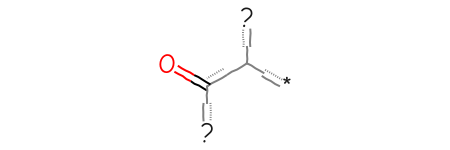

In [5]:
Chem.MolFromSmarts(D_smarts)

In [6]:
###################################################################
# iterate over all SMARTS to find those ncAAs which match a, b, y #
###################################################################

matching_dict = {}
mol_matching_dict = {}

aa_qry = Chem.MolFromSmarts(D_smarts)
aa_matching = []
mol_matching = []

for SMILES, ID in zip(ncaa_df['SMILES'], ncaa_df['ID']):

  #  if ID not in total_liste:
   #     print(ID, SMILES)

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if mol.HasSubstructMatch(aa_qry, useChirality=True): #, useChirality=False, useEnhancedStereo=False, NoImplicitH ):
            
            aa_matching.append(ID)
            mol_matching.append(mol)
            # total_liste.append(ID)
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print('\nAmounts:', len(aa_matching))
methyl_list = aa_matching
# print('β:', aa_matching)
print('YWF' in aa_matching)

Problem of valence, not parsed:  A1DEJ
Problem of valence, not parsed:  A1IPL
Problem of valence, not parsed:  A1ITS
Problem of valence, not parsed:  2AS

Amounts: 118
False


[21:15:17] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:15:17] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:15:17] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:15:17] Explicit valence for atom # 5 C, 6, is greater than permitted


In [7]:
methyl_list

['D0C',
 'TDF',
 'BF7',
 'F9D',
 'C0O',
 'DHV',
 'MV9',
 'E03',
 'MND',
 'TDD',
 '7YO',
 'A1AP1',
 'ZUK',
 'IOY',
 'HTN',
 'KW4',
 'DTH',
 'CCJ',
 'MED',
 'ORD',
 'DNE',
 'DLY',
 '2TL',
 'HMF',
 'DSE',
 'DAS',
 'ZAE',
 'DIL',
 'API',
 'DSG',
 'DHI',
 '28J',
 'DAR',
 'DCY',
 'DGN',
 'DGL',
 '4J2',
 'DTY',
 'DTR',
 'DPN',
 'DSN',
 'DLE',
 'DPR',
 'MLU',
 'FGA',
 'DVA',
 'DAL',
 'DBB',
 'GHP',
 'OMZ',
 'ACB',
 '4FO',
 '3MY',
 'V7T',
 'ZAL',
 '2RA',
 'CPI',
 'DFF',
 'D3P',
 'A1EAK',
 'PRV',
 'FH7',
 'EE0',
 'HJV',
 '33X',
 'KFP',
 '7XC',
 'DNM',
 '00C',
 'HTY',
 'OGC',
 '0UZ',
 'OWF',
 'PG9',
 'KJW',
 '060',
 'MSA',
 '6CL',
 '4N3',
 'UYA',
 'A1BIT',
 'A1EJL',
 'ZTG',
 'ZSX',
 'YBR',
 'NCB',
 'RF9',
 'OV7',
 'SWW',
 'Q3S',
 'VDL',
 'OEM',
 'OHS',
 'SNK',
 'A1CLH',
 'A1D5P',
 'A1EDD',
 'A1EQM',
 '9R4',
 'A1A2K',
 'A1AZ2',
 'A1AQ4',
 '1JM',
 '1IC',
 '99Y',
 '45W',
 'HT0',
 'HGM',
 'IGL',
 'F93',
 'MGG',
 'KCY',
 'K5L',
 'LEI',
 'HJY',
 'D11',
 'DYL',
 'DNG']

In [8]:
#################################################### 
# get <10 atoms (smaller than glycine) components  #
####################################################

caps = []

for SMILES, ID in zip(ncaa_df['SMILES'], ncaa_df['ID']):

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if mol.GetNumAtoms(onlyExplicit=False) < 10:
            
            caps.append(ID)
            
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print('\ncaps: (<10 atoms)', len(caps))
print(caps)

Problem of valence, not parsed:  A1DEJ
Problem of valence, not parsed:  A1IPL
Problem of valence, not parsed:  A1ITS
Problem of valence, not parsed:  2AS

caps: (<10 atoms) 25
['NME', '0QE', 'NH2', 'ACE', 'CF0', 'GLZ', 'ACY', 'FMT', 'GOA', 'XZA', 'TEE', 'R3W', 'MCR', 'HOA', 'FOR', 'AZI', '0HQ', 'ARF', 'MOH', 'ACT', 'CFT', 'URE', 'AKR', 'FPA', 'E1H']


[21:15:27] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:15:27] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:15:27] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:15:27] Explicit valence for atom # 5 C, 6, is greater than permitted


In [9]:
print('Length of canonical amino acids:')
      
for aa, smiles in zip(canonicalAAs, canonicalAA_smiles):

    mol = Chem.MolFromSmiles(smiles)
    print(aa, mol.GetNumAtoms(onlyExplicit=False))

Length of canonical amino acids:
ALA 13
ARG 27
ASN 17
ASP 16
CYS 14
GLN 20
GLU 19
GLY 10
HIS 21
ILE 22
LEU 22
LYS 25
MET 20
PHE 23
PRO 17
SER 14
THR 17
TRP 27
TYR 24
VAL 19


In [10]:
import os
os.getcwd()

'C:\\Users\\Alexandra\\OneDrive - uibk.ac.at\\Dokumente\\2024 PhD\\mondet-update-nov-3'

In [35]:
##################################################################
# get >10 atoms and <14 atoms (smaller than glycine) components  #
##################################################################

hannes = {}

for SMILES, ID, entity_count in zip(ncaa_df['SMILES'], ncaa_df['ID'], ncaa_df['entity_count']):

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if (mol.GetNumAtoms(onlyExplicit=False) >= 10) and (mol.GetNumAtoms(onlyExplicit=False) <= 27):
            
            hannes[ID] = {'SMILES': SMILES, 'num_atoms': mol.GetNumAtoms(onlyExplicit=False),'entity_count': entity_count}
            
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print('IDs possibly useful for Boltz (>= 10, <=27):', len(hannes))
hannes_df = pd.DataFrame.from_dict(hannes, orient='index')
hannes_df.to_csv("total_14_atoms-27-atoms.csv", sep=";")


####################################
# Find alpha-amino acid candidates #
####################################

aa_qry = Chem.MolFromSmarts(L_smarts)

hannes = {}

for SMILES, ID, entity_count in zip(hannes_df['SMILES'], hannes_df.index, hannes_df['entity_count']):

    print(SMILES, ID, entity_count)

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if mol.HasSubstructMatch(aa_qry, useChirality=False):

            hannes[ID] = {'SMILES': SMILES, 'num_atoms': mol.GetNumAtoms(onlyExplicit=False),'entity_count': entity_count, 'aa-acid': 'likely'}
            
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print(hannes)

print('AA likely: IDs possibly useful for Boltz (>= 10, <=27, aa search):', len(hannes))
hannes_df = pd.DataFrame.from_dict(hannes, orient='index')
hannes_df
#hannes_df.to_csv("total_14_atoms-27-atoms-ALPHA-AMINO-ACID.csv", sep=";")

[18:46:17] Explicit valence for atom # 5 C, 6, is greater than permitted
[18:46:17] Explicit valence for atom # 0 B, 4, is greater than permitted
[18:46:17] Explicit valence for atom # 10 N, 4, is greater than permitted


Problem of valence, not parsed:  2AS
Problem of valence, not parsed:  A1IPL
Problem of valence, not parsed:  WGB
IDs possibly useful for Boltz (>= 10, <=27): 1042
CC(C)C[C@@H](C(=O)O)N LEU 463592
C[C@@H](C(=O)O)N ALA 462445
C(C(=O)O)N GLY 460946
C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N ARG 460565
C(CC[NH3+])C[C@@H](C(=O)O)N LYS 459778
CC(C)[C@@H](C(=O)O)N VAL 459203
C([C@@H](C(=O)O)N)O SER 459160
C[C@H]([C@@H](C(=O)O)N)O THR 457879
C(CC(=O)O)[C@@H](C(=O)O)N GLU 456150
C1C[C@H](NC1)C(=O)O PRO 455767
CC[C@H](C)[C@@H](C(=O)O)N ILE 455125
C([C@@H](C(=O)O)N)C(=O)O ASP 453020
C([C@@H](C(=O)O)N)C(=O)N ASN 452736
C(CC(=O)N)[C@@H](C(=O)O)N GLN 452497
c1ccc(cc1)C[C@@H](C(=O)O)N PHE 449711
c1cc(ccc1C[C@@H](C(=O)O)N)O TYR 445897
c1c([nH+]c[nH]1)C[C@@H](C(=O)O)N HIS 434541
CSCC[C@@H](C(=O)O)N MET 427175
c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N TRP 363296
C([C@@H](C(=O)O)N)S CYS 351270
C[Se]CC[C@@H](C(=O)O)N MSE 10702
CC[C@@H](C(=O)O)N UNK 3776
C([C@@H](C(=O)O)N)OP(=O)(O)O SEP 2030
C[C@H]([C@@H](C(=O)O)N)OP(=O)

,SMILES,num_atoms,entity_count,aa-acid
LEU,CC(C)C[C@@H](C(=O)O)N,22,463592,likely
ALA,C[C@@H](C(=O)O)N,13,462445,likely
ARG,C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N,27,460565,likely
LYS,C(CC[NH3+])C[C@@H](C(=O)O)N,25,459778,likely
VAL,CC(C)[C@@H](C(=O)O)N,19,459203,likely
...,...,...,...,...
ZI0,C1CC(N(C1)C(=O)CC(=O)O)C(=O)O,25,1,likely
ZNY,CCO[C@@H]1C[C@H](NC1)C(=O)O,24,1,likely
ZSX,COc1ccc(cc1)[C@H](C(=O)O)N,24,1,likely
ZTK,C(C#N)[C@@H](C(=O)O)N,14,1,likely


## b) Classification by canonical amino acid

* [X] search the set (stereochemically insensitive) for every amino acid and save to a dictionary of lists
* [X] cut down the lists to filter unique sets (e.g. Ala-list should not be contained in Tyr-list)
* [X] make a list of those which fit nothing
* [X] check if everything was covered

Helpful for the work with sets: https://www.cheat-sheets.org/saved-copy/Python-Set-Methods-Cheat-Sheet.20210604.pdf

Helpful to work with SMARTS: https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html

### Define canonical SMARTS


* Trp - Tyr - Phe
* His - Lys - Arg - Ile - Leu - Met - Pro
* Gln - Asn
* Glu - Asp
* Cys - Thr - Val
* Ala - Ser
* Gly

In [11]:
########################################################
# 

canonicalAAs = ['ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLN', 'GLU', 'GLY', 'HIS', 'ILE', 'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL']
               
canonicalAA_dict = {
    'TRP': {'SMARTS': 'c1ccc2c(c1)c(c[nH]2)C~C(C~[O])[N]C'},  # Side chain: aromatic preserved, alkyl any bond [*]
    'TYR': {'SMARTS': 'c1cc(O)ccc1C~C(C~[O])[N]C'},  # Phenol ring + alkyl
    'PHE': {'SMARTS': 'c1ccc(cc1)C~C(C~[O])[N]C'},  # Phenyl + alkyl
    'HIS': {'SMARTS': 'c1c[nH]c[nH]1C~C(C~[O])[N]C'},  # Imidazole neutral/low charge
    'LYS': {'SMARTS': 'C~C~C~[N]C~C(C~[O])[N]C'},  # Long chain ending any N
    'ARG': {'SMARTS': 'C~C(NC~[N])[N]C~C(C~[O])[N]C'},  # Guanidino-like with any bonds/N
    'ILE': {'SMARTS': 'C~C(C)C(C~[O])[N]C'},  # Branched alkyl *
    'LEU': {'SMARTS': 'C(C)C~C(C~[O])[N]C'},  # Isobutyl chain
    'MET': {'SMARTS': '[#16]~C~C~C(C~[O])[N]C'},  # Thioether, [#16] for S/Se
    'PRO': {'SMARTS': 'C1CC(NC1)C~[O]'},  # Ring pyrrolidine
    'GLN': {'SMARTS': 'C~C~C(=O)[N]C(C~[O])[N]C'},  # Any chain to amide (length via ~)
    'GLU': {'SMARTS': 'C~C~C(=O)[O]C(C~[O])[N]C'},  # Any chain to carboxy
    'ASN': {'SMARTS': 'C(C(=O)[N])C~[O][N]C'},  # Alpha C with amide
    'ASP': {'SMARTS': 'C(C(=O)[O])C~[O][N]C'},  # Alpha C with carboxy
    'CYS': {'SMARTS': 'C([*])[C](C~[O])[N]C'},  # Side * for S/Se/any
    'THR': {'SMARTS': 'C(O)C(O)[N]C(C~[O])'},  # Note: beta OH on generic C
    'VAL': {'SMARTS': 'C(C)(C)C(C~[O])[N]C'},  # Isopropyl
    'SER': {'SMARTS': 'C([O])C(C~[O])[N]C'},  # CH2OH → C-O
    'ALA': {'SMARTS': 'C(C~[O])[N]C'},  # Methyl
    'GLY': {'SMARTS': 'C(C~[O])[N]C'}  # H implicit in *
}

canonicalAA_dict = {'TRP': {'SMARTS': 'c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N'},
                      'TYR': {'SMARTS': 'c1cc(ccc1C[C@@H](C(=O)O)N)O'},
                      'PHE': {'SMARTS': 'c1ccc(cc1)C[C@@H](C(=O)O)N'},
                      # 'HIS': {'SMARTS': 'c1c([nH+]c[nH]1)C[C@@H](C(=O)O)N'},
                      'HIS': {'SMARTS': 'c1c([n]c[n]1)C[C@@H](C(=O)O)N'},
                      # 'LYS': {'SMARTS': 'C(CC[NH3+])C[C@@H](C(=O)O)N'},
                      'LYS': {'SMARTS': 'C(CC[N])C[C@@H](C(=O)O)N'},
                      # 'ARG': {'SMARTS': 'C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N'},
                      'ARG': {'SMARTS': 'C(C[C@@H](C(=O)O)N)CNC(=[N])N'},
                      'ILE': {'SMARTS': 'CC[C@H](C)[C@@H](C(=O)O)N'},
                      'LEU': {'SMARTS': 'CC(C)C[C@@H](C(=O)O)N'},
                      'MET': {'SMARTS': 'CSCC[C@@H](C(=O)O)N'},
                      'PRO': {'SMARTS': 'C1C[C@H](NC1)C(=O)O'},
                      'GLN': {'SMARTS': 'C(CC(=O)N)[C@@H](C(=O)O)N'},
                      'GLU': {'SMARTS': 'C(CC(=O)O)[C@@H](C(=O)O)N'},
                      'ASN': {'SMARTS': 'C([C@@H](C(=O)O)N)C(=O)N'},
                      'ASP': {'SMARTS': 'C([C@@H](C(=O)O)N)C(=O)O'},
                      'CYS': {'SMARTS': 'C([C@@H](C(=O)O)N)S'},
                      'THR': {'SMARTS': 'C[C@H]([C@@H](C(=O)O)N)O'},
                      'VAL': {'SMARTS': 'CC(C)[C@@H](C(=O)O)N'},
                      'SER': {'SMARTS': 'C([C@@H](C(=O)O)N)O'},
                      'ALA': {'SMARTS': 'C[C@@H](C(=O)O)N'},
                      'chromophore': {'SMARTS': 'C1~[N,n]~C~C(=O)~[N,n]~1'}, 
                      'GLY': {'SMARTS': 'C(C(=O)O)N'}}


In [12]:
#################################################
# DEF: add row to the dataframe                 #
#################################################

def add_row(df, ID, SMILES, entity_count, parent):
    
    new_row = pd.DataFrame({"ID": [ID],
                            "SMILES": [SMILES],
                            "entity_count": [entity_count],
                            "parent": [parent]})
    
    df = pd.concat([df, new_row], ignore_index=True)

    return df 


In [13]:
canonicalAA_dict.keys()

dict_keys(['TRP', 'TYR', 'PHE', 'HIS', 'LYS', 'ARG', 'ILE', 'LEU', 'MET', 'PRO', 'GLN', 'GLU', 'ASN', 'ASP', 'CYS', 'THR', 'VAL', 'SER', 'ALA', 'chromophore', 'GLY'])

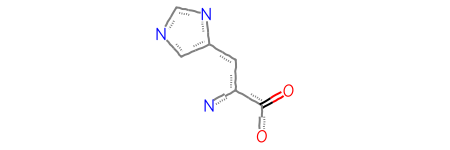

In [14]:
Chem.MolFromSmarts('c1c([n]c[n]1)C[C@@H](C(=O)O)N')

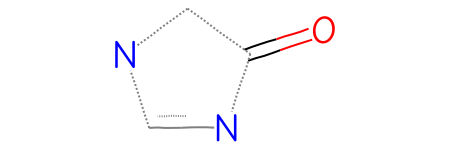

In [15]:
Chem.MolFromSmarts('C1~n~C~C(=O)~n1')

### ncAA SMILES loading

In [16]:
########################################################
# !! Load the updated ncaa_dataframe                   #
########################################################

#described_ncaa_df = pd.read_csv("updated_to_1000_PDB_described_protein_2026_04_Apr.csv", sep=";")  # !!! change in an update
described_ncaa_df = pd.read_csv("protein_list_for_coding_06_Nov_2026.csv", sep=";")
#described_ncaa_df = pd.read_csv("Waldherr_Freimann_MONDET_Apr_2025_protein.csv", sep=";")
ncaa_df = described_ncaa_df[['SMILES', 'ID', 'entity_count']]
ncaa_df

,SMILES,ID,entity_count
0,c1c[nH]c2c1c(ncn2)N3CCNCC3,6J9,6
1,c1cc(ccc1c2ccc(cc2)OP(=O)(O)O)C(=O)O,A1B60,4
2,COC(=O)CC[C@H](C(=O)OC)N,A1B6Z,4
3,c1cc(c2c(c1NCCC(=O)O)non2)N(=O)=O,UQ4,6
4,C(CCCC(=O)O)CCCC(=O)O,AZ1,3
...,...,...,...
1990,C[C@H](/C=C(\C)/[C@@H](C)N)C(=O)O,CFD,1
1991,C([C@@H](C(O)(O)O)N)C(=O)N,CE7,1
1992,CC(C)[C@@H](C)N,CDE,1
1993,c1cc(ccc1CC2C(=O)N(C(N2)[C@H](CS)N)CC(=O)O)O,CCY,1


In [17]:
###################################################
# def CANONICAL QUERY                             #
###################################################

def canonical_query(canonicalAA, canonicalAA_dict, ncaa_df, negative_examples, ncaa_classes_df):

    # ncaa_classes_df = to store the data
    # canonicalAA = ID (e.g. ALA)
    # canonicalAA_dict = master dict with ['ALA']: {'SMARTS': ..., 'aa_matching': ..., 'mol_matching': ...}

    aa_smarts = canonicalAA_dict[canonicalAA]['SMARTS']    # get the SMARTS saved to it
    aa_qry = Chem.MolFromSmarts(aa_smarts)   #  make a query molecule from it
    
    aa_matching = []
    mol_matching = []

    for SMILES, ID, entity_count in zip(ncaa_df['SMILES'], ncaa_df['ID'], ncaa_df['entity_count']):

        if ID in negative_examples:
            continue

        else:
            
            try:
                mol = Chem.MolFromSmiles(SMILES)
                
                if mol.HasSubstructMatch(aa_qry, useChirality=False): #, useChirality=False, useEnhancedStereo=False, NoImplicitH

                    aa_matching.append(ID)
                    mol_matching.append(mol)
                    negative_examples.append(ID)    # save this to not use it for another amino acids with less priority

                    ncaa_classes_df = add_row(ncaa_classes_df, ID, SMILES, entity_count, canonicalAA)

                    if canonicalAA == "GLY":
                        print(SMILES)
                    else:
                        None
                    
            except:
                continue  # A1IPL, A1ITS, WGB, 2AS create problems

    canonicalAA_dict[f'{canonicalAA}']['aa_matching'] = aa_matching
    canonicalAA_dict[f'{canonicalAA}']['mol_matching'] = mol_matching
    canonicalAA_dict[f'{canonicalAA}']['unique_children'] = len(aa_matching)
    
    return canonicalAA_dict, negative_examples, ncaa_classes_df

In [18]:
###################################################################
# iterate over all canonical AAs and find those ncAAs which match #
###################################################################

# array to store the labels for parsing on the website
ncaa_classes_df = pd.DataFrame()
ncaa_classes_df = ncaa_classes_df.assign(**{col: '' for col in ["ID", "SMILES", "entity_count", "parent"]})

# start the run
negative_examples = []

for aa in canonicalAA_dict.keys():

    canonicalAA_dict, negative_examples, ncaa_classes_df = canonical_query(aa, canonicalAA_dict, ncaa_df, negative_examples, ncaa_classes_df)

    # sanity check if it finds itself
    if aa in canonicalAA_dict[f'{aa}']['aa_matching']:
        print(f'{aa} has found itself')
    elif aa not in canonicalAA_dict[f'{aa}']['aa_matching']:
        print(f'! {aa} has NOT FOUND itself')

[21:16:38] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:16:38] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:16:38] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:16:38] Explicit valence for atom # 5 C, 6, is greater than permitted


TRP has found itself


[21:16:39] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:16:39] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:16:39] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:16:39] Explicit valence for atom # 5 C, 6, is greater than permitted


TYR has found itself


[21:16:39] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:16:39] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:16:39] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:16:39] Explicit valence for atom # 5 C, 6, is greater than permitted


PHE has found itself


... (31 outputs left out)

ALA has found itself


[21:16:47] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:16:47] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:16:47] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:16:47] Explicit valence for atom # 5 C, 6, is greater than permitted


! chromophore has NOT FOUND itself
C1CNCCC1(C(=O)O)N
CC(=C(C(=O)O)N)C
CC/C(=C(\C(=O)O)/N)/C
CCCC[C@](C)(C(=O)O)N
C(=C(/C(=O)O)\N)\NC(=O)N
CCCC[C@@](C)(C(=O)O)N
CC(C)(C(=O)O)N
CNCC(=O)O
C(C(=O)O)N
C=C(C(=O)O)N
c1cc(ccc1[C@H](C(=O)O)N)O
c1c(cc(cc1O)O)[C@@H](C(=O)O)N
C\C=C(\C(=O)O)/N
C[C@](CCC(=O)N)(C(=O)O)N
C(=C(\C(=O)O)/N)/S
c1ccc(cc1)[C@@H](C(=O)O)N
CNC(=C)C(=O)O
CC[C@](C)(C(=O)O)N
C1[C@@H](C(=O)N(C1=O)CC(=O)O)N
C1CCC(C1)(C(=O)O)N
C(=C(/C(=O)O)\N)\C(=O)O
COc1ccc(cc1C(=O)NN)NC(=O)C(=O)O
CCCCCCC[C@](C)(C(=O)O)N
CC(C)C[C@@](C)(C(=O)O)N
C[C@]1(CCCN1)C(=O)O
c1cc(ccc1[C@@H](C(=O)O)N)O
C\C=C(\C(=O)O)/NC
C1COCCN1CC(=O)O
C/C(=C(\C(=O)O)/N)/S
C1C[C@](NC1)(C(=O)O)O
CC[C@@](C)(C(=O)O)N
C[C@](CCCC=C)(C(=O)O)N
C1CCC(CC1)(C(=O)O)N
CC(=O)NCC(=O)O
CN[C@@H](c1ccc(cc1)O)C(=O)O
COC/C(=C(\C(=O)O)/N)/S
c1ccc(cc1)C(=O)NCC(=O)O
C1CC1(C(=O)O)N
C[C@](CCCCN)(C(=O)O)N
C(=C(/C(=O)O)\N)\[SeH]
CN(C)CC(=O)O
c1c(cc(cc1O)O)[C@H](C(=O)O)N
C[C@](Cc1ccccc1)(C(=O)O)N
c1ccc(c(c1)CNCC(=O)O)N(=O)=O
CCCCCC[C@H]([C@@H](C)C(=O)O

[21:16:47] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:16:47] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:16:47] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:16:47] Explicit valence for atom # 5 C, 6, is greater than permitted


In [19]:
# draw the subsets

for aa_mol in canonicalAA_dict.keys():
    print(f"{aa_mol} MATCHES {len(canonicalAA_dict[aa_mol]['mol_matching'])}")
    #img = Draw.MolsToGridImage(canonicalAA_dict[aa_mol]['mol_matching'][:9], subImgSize=(80,80))
    #display(img)
print(f"Total found: {len(negative_examples)}")

TRP MATCHES 35
TYR MATCHES 65
PHE MATCHES 112
HIS MATCHES 28
LYS MATCHES 127
ARG MATCHES 35
ILE MATCHES 19
LEU MATCHES 52
MET MATCHES 18
PRO MATCHES 54
GLN MATCHES 22
GLU MATCHES 14
ASN MATCHES 12
ASP MATCHES 24
CYS MATCHES 132
THR MATCHES 29
VAL MATCHES 28
SER MATCHES 72
ALA MATCHES 242
chromophore MATCHES 96
GLY MATCHES 137
Total found: 1353


**November 2026**

TRP MATCHES 35
TYR MATCHES 65
PHE MATCHES 112
HIS MATCHES 28
LYS MATCHES 127
ARG MATCHES 35
ILE MATCHES 19
LEU MATCHES 52
MET MATCHES 18
PRO MATCHES 54
GLN MATCHES 22
GLU MATCHES 14
ASN MATCHES 12
ASP MATCHES 24
CYS MATCHES 132
THR MATCHES 29
VAL MATCHES 28
SER MATCHES 72
ALA MATCHES 242
chromophore MATCHES 96
GLY MATCHES 137
Total found: 1353

**April 2026**

TRP MATCHES 35
TYR MATCHES 64
PHE MATCHES 103
HIS MATCHES 28
LYS MATCHES 120
ARG MATCHES 32
ILE MATCHES 18
LEU MATCHES 52
MET MATCHES 17
PRO MATCHES 52
GLN MATCHES 23
GLU MATCHES 12
ASN MATCHES 11
ASP MATCHES 24
CYS MATCHES 135
THR MATCHES 28
VAL MATCHES 28
SER MATCHES 70
ALA MATCHES 223
chromophore MATCHES 93
GLY MATCHES 126
Total found: 1294

In [20]:
# Nov 2026, Apr 2026, Oct 2025, Apr 2025
1353 - 96, 1323 - 93, 1294 - 93, 1262 - 90 

(1257, 1230, 1201, 1172)

In [22]:
ncaa_classes_df

,ID,SMILES,entity_count,parent
0,E03,c1cc2c(cc1F)[nH]cc2C[C@H](C(=O)O)N,1,TRP
1,DTR,c1ccc2c(c1)c(c[nH]2)C[C@H](C(=O)O)N,130,TRP
2,TRP,c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N,432540,TRP
3,FTR,c1cc2c(cc1F)c(c[nH]2)C[C@@H](C(=O)O)N,44,TRP
4,0AF,c1cc2c(c[nH]c2c(c1)O)C[C@@H](C(=O)O)N,29,TRP
...,...,...,...,...
1348,KPN,c1ccnc(c1)c2ccc(cn2)CC(=O)N(CCN)CC(=O)O,1,GLY
1349,L4R,C[C@@](CCCCCCC=C)(C(=O)O)N,1,GLY
1350,CPC,C[C@H]1C[C@]1(C(=O)O)NC,1,GLY
1351,EJJ,C(C(=O)O)NC(=O)N,1,GLY


TRP MATCHES 35


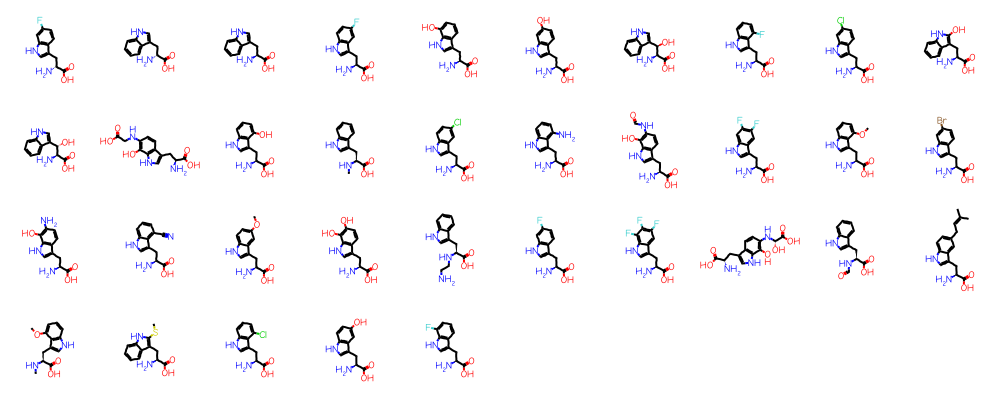

TYR MATCHES 65


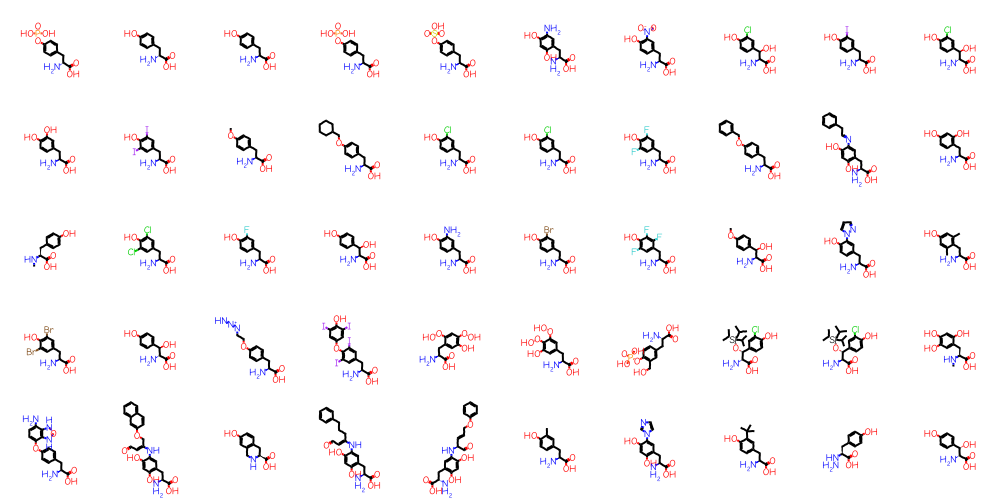

PHE MATCHES 112


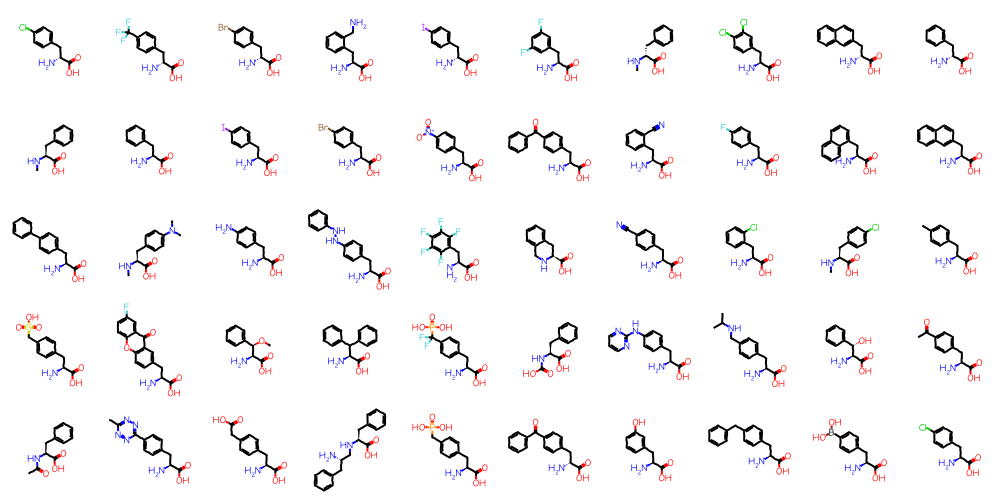

HIS MATCHES 28


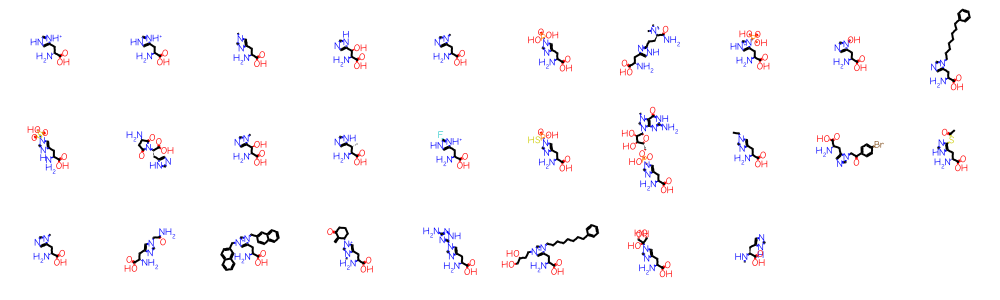

LYS MATCHES 127


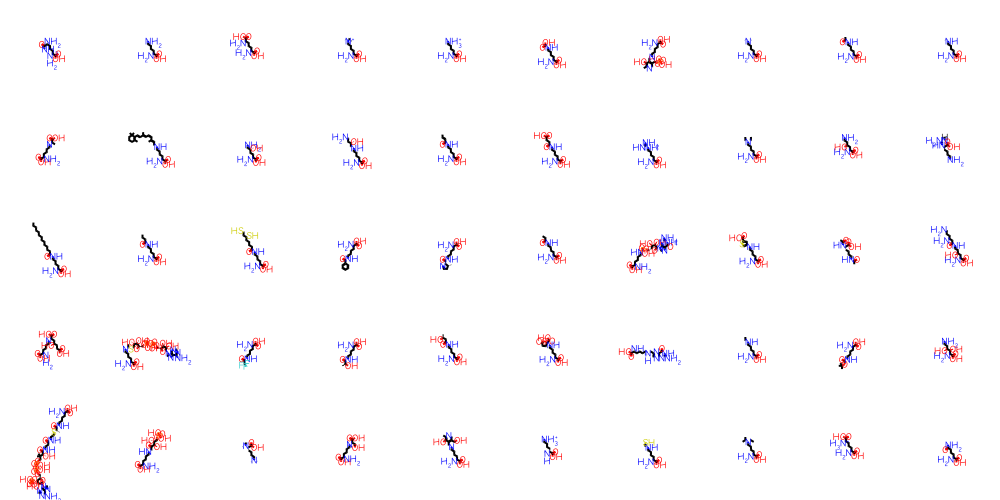

ARG MATCHES 35


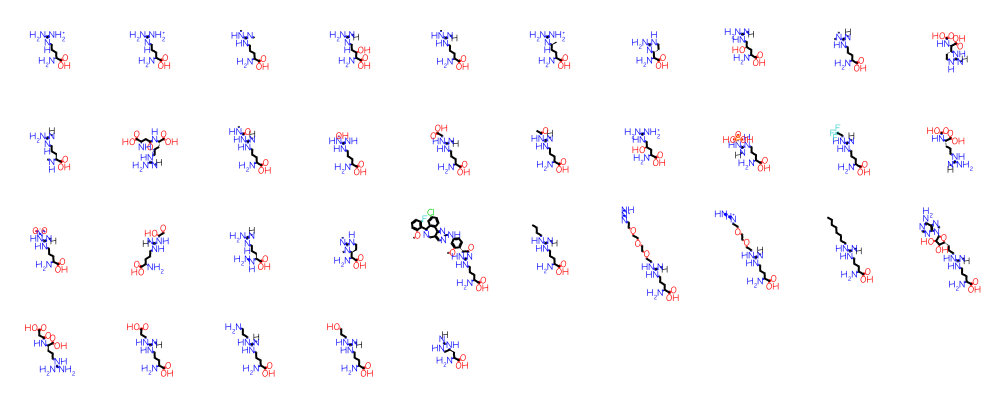

ILE MATCHES 19


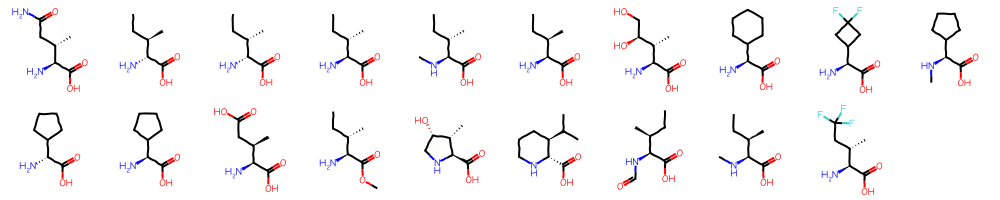

LEU MATCHES 52


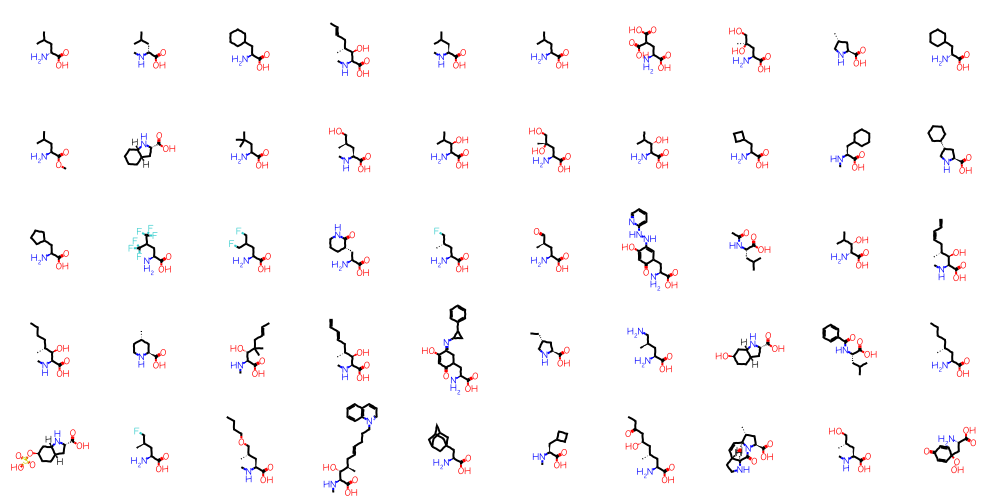

MET MATCHES 18


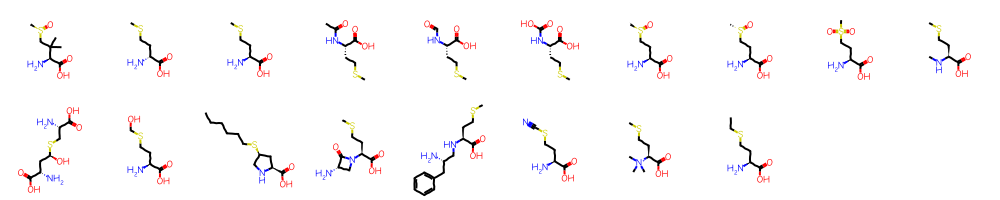

PRO MATCHES 54


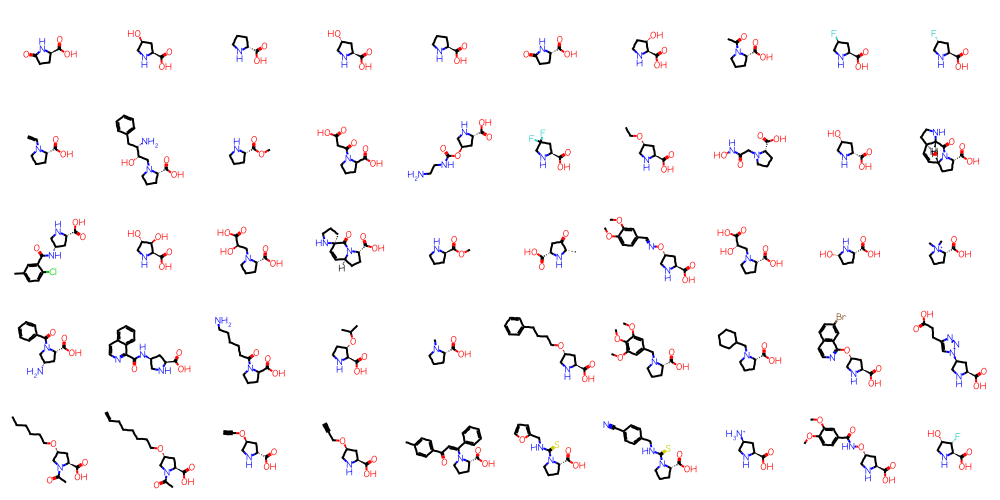

GLN MATCHES 22


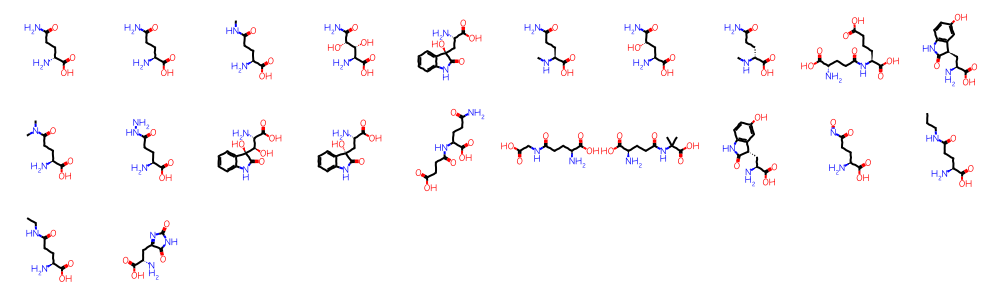

GLU MATCHES 14


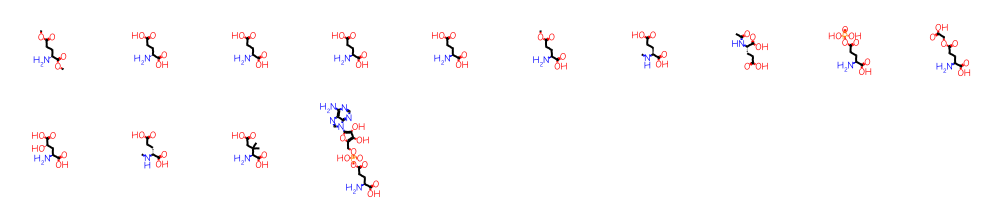

ASN MATCHES 12


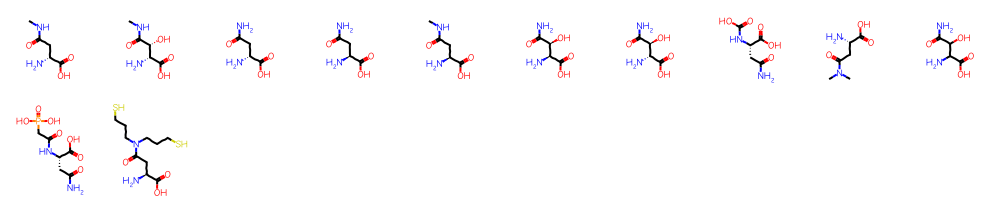

ASP MATCHES 24


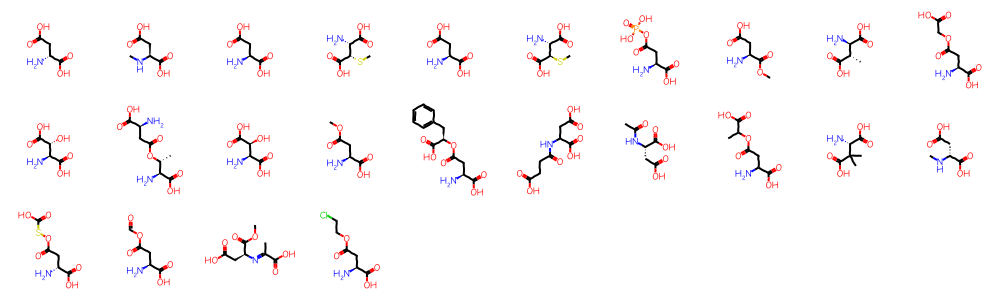

CYS MATCHES 132


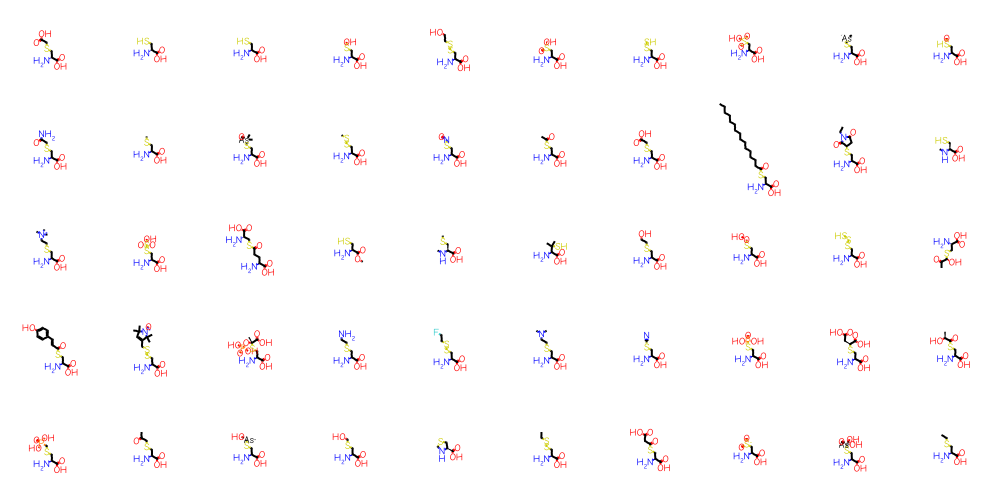

THR MATCHES 29


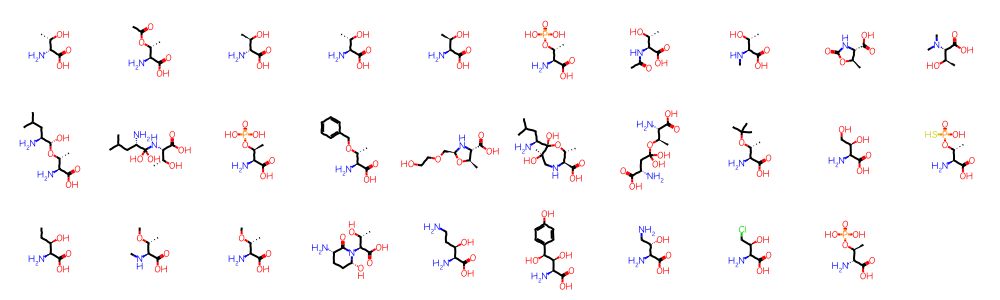

VAL MATCHES 28


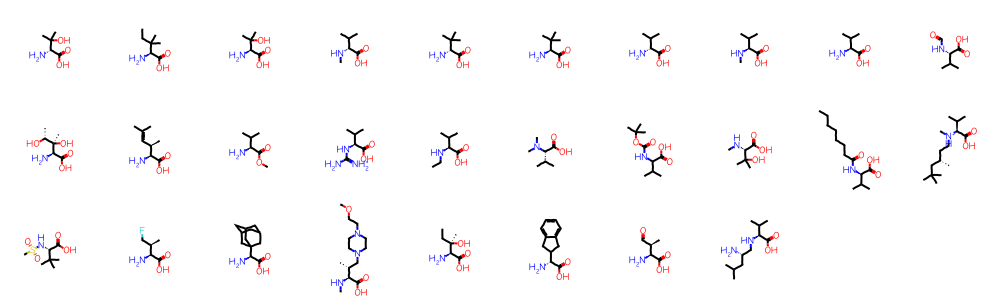

SER MATCHES 72


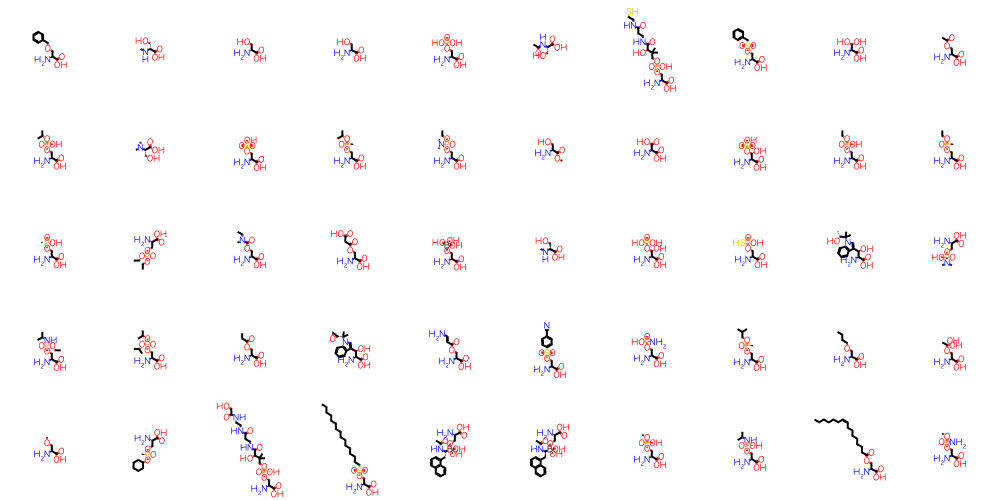

ALA MATCHES 242


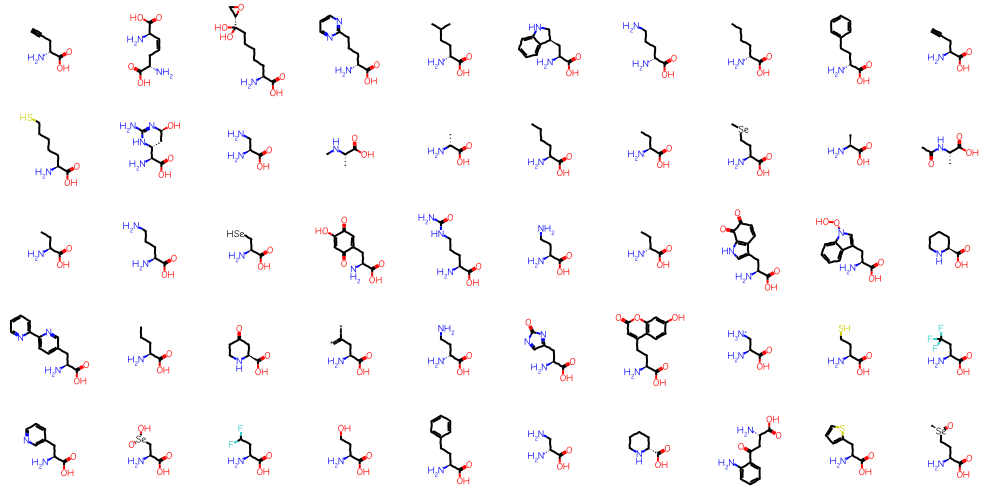

chromophore MATCHES 96


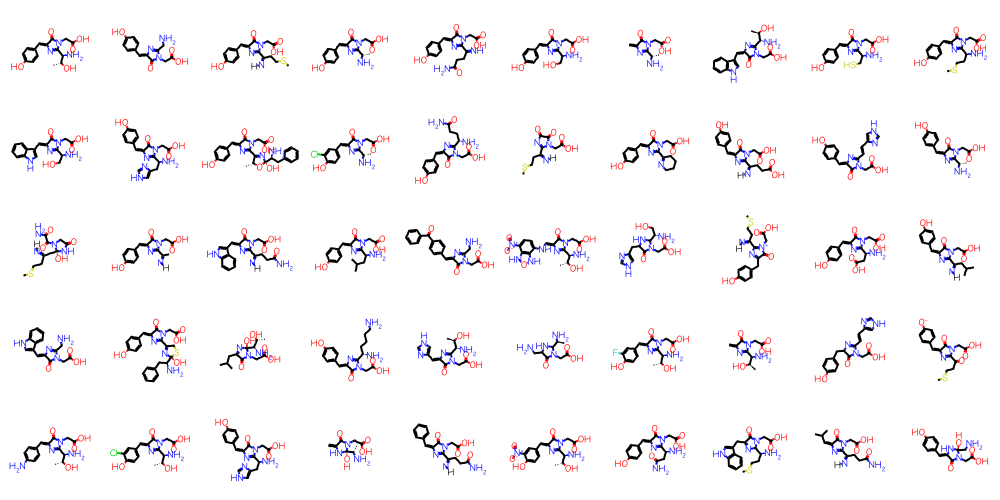

GLY MATCHES 137


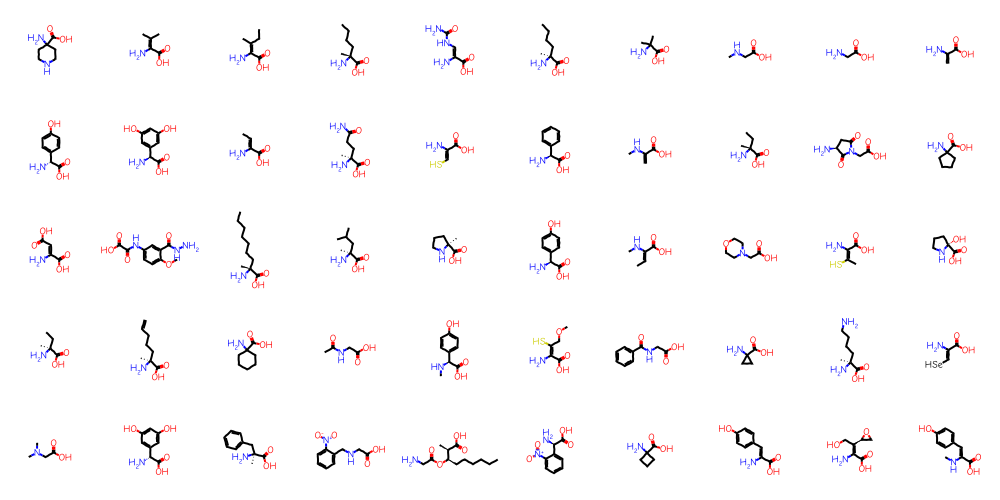

In [23]:
# draw the subsets

for aa_mol in canonicalAA_dict.keys():
    print(f"{aa_mol} MATCHES {len(canonicalAA_dict[aa_mol]['mol_matching'])}")
    img = Draw.MolsToGridImage(canonicalAA_dict[aa_mol]['mol_matching'][:50], molsPerRow=10, subImgSize=(100,100))
    display(img)

In [26]:
#####################
# NOVEMBER 2026     #
#####################

canonical_found_df = pd.DataFrame(canonicalAA_dict)
canonical_found_df.sort_index(axis=1, inplace=True)
canonical_found_df.drop('mol_matching', axis=0, inplace=True)
canonical_found_df

,ALA,ARG,ASN,ASP,CYS,GLN,GLU,GLY,HIS,ILE,...,LYS,MET,PHE,PRO,SER,THR,TRP,TYR,VAL,chromophore
SMARTS,C[C@@H](C(=O)O)N,C(C[C@@H](C(=O)O)N)CNC(=[N])N,C([C@@H](C(=O)O)N)C(=O)N,C([C@@H](C(=O)O)N)C(=O)O,C([C@@H](C(=O)O)N)S,C(CC(=O)N)[C@@H](C(=O)O)N,C(CC(=O)O)[C@@H](C(=O)O)N,C(C(=O)O)N,c1c([n]c[n]1)C[C@@H](C(=O)O)N,CC[C@H](C)[C@@H](C(=O)O)N,...,C(CC[N])C[C@@H](C(=O)O)N,CSCC[C@@H](C(=O)O)N,c1ccc(cc1)C[C@@H](C(=O)O)N,C1C[C@H](NC1)C(=O)O,C([C@@H](C(=O)O)N)O,C[C@H]([C@@H](C(=O)O)N)O,c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N,c1cc(ccc1C[C@@H](C(=O)O)N)O,CC(C)[C@@H](C(=O)O)N,"C1~[N,n]~C~C(=O)~[N,n]~1"
aa_matching,"[F9D, C0O, 5OM, ZUK, KW4, A1H2D, ORD, DNE, HMF...","[DAR, ARG, 2MR, 4D4, NMM, AGM, MYN, WYK, DA2, ...","[MND, HTN, DSG, ASN, MEN, AHB, OWF, 5VV, DMH, ...","[DAS, SOQ, ASP, 0TD, IAS, D2T, PHD, 5F0, ACB, ...","[CCJ, DCY, CYS, CSO, CME, CSD, CSS, OCS, CAS, ...","[DGN, GLN, MEQ, R2T, RE0, GNC, GHG, HJV, R0K, ...","[A1B6Z, DGL, FGA, GLU, GGL, GME, EME, NLG, VHF...","[A1L9X, RXL, RX9, 2JN, UAL, MK8, AIB, SAR, GLY...","[DHI, HIS, HIC, V5N, MHS, NEP, DDE, HIP, HSK, ...","[LMQ, DIL, 28J, ILE, IML, IIL, ILX, CHG, A1MJF...",...,"[JGO, DLY, API, M3L, LYS, KCX, LLP, MLY, ALY, ...","[M2S, MED, MET, AME, FME, CXM, SME, MHO, OMT, ...","[D0C, TDF, BF7, LWI, IOY, WFP, ZAE, ZCL, 4J2, ...","[7YO, HZP, DPR, HYP, PRO, PCA, HY3, N7P, 4FB, ...","[SEM, DSE, DSN, SER, SEP, SAC, 4HH, SEB, DDZ, ...","[DTH, TH5, 2TL, ALO, THR, TPO, THC, NZC, OZT, ...","[E03, DTR, TRP, FTR, 0AF, TRX, UX8, 4FW, 6CW, ...","[A1AP1, DTY, TYR, PTR, TYS, TYQ, NIY, OMY, IYR...","[DHV, I2M, HVA, MV9, TDD, TBG, DVA, MVA, VAL, ...","[CRO, CR2, NRQ, PIA, CRQ, GYS, MDO, CRF, GYC, ..."
unique_children,242,35,12,24,132,22,14,137,28,19,...,127,18,112,54,72,29,35,65,28,96


In [354]:
#####################
# APRIL 2026        #
#####################

#canonical_found_df = pd.DataFrame(canonicalAA_dict)
#canonical_found_df.sort_index(axis=1, inplace=True)
#canonical_found_df.drop('mol_matching', axis=0, inplace=True)
#canonical_found_df

,ALA,ARG,ASN,ASP,CYS,GLN,GLU,GLY,HIS,ILE,...,LYS,MET,PHE,PRO,SER,THR,TRP,TYR,VAL,chromophore
SMARTS,C[C@@H](C(=O)O)N,C(C[C@@H](C(=O)O)N)CNC(=[N])N,C([C@@H](C(=O)O)N)C(=O)N,C([C@@H](C(=O)O)N)C(=O)O,C([C@@H](C(=O)O)N)S,C(CC(=O)N)[C@@H](C(=O)O)N,C(CC(=O)O)[C@@H](C(=O)O)N,C(C(=O)O)N,c1c([n]c[n]1)C[C@@H](C(=O)O)N,CC[C@H](C)[C@@H](C(=O)O)N,...,C(CC[N])C[C@@H](C(=O)O)N,CSCC[C@@H](C(=O)O)N,c1ccc(cc1)C[C@@H](C(=O)O)N,C1C[C@H](NC1)C(=O)O,C([C@@H](C(=O)O)N)O,C[C@H]([C@@H](C(=O)O)N)O,c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N,c1cc(ccc1C[C@@H](C(=O)O)N)O,CC(C)[C@@H](C(=O)O)N,"C1~[N,n]~C~C(=O)~[N,n]~1"
aa_matching,"[U2M, 5OH, ABA, ALA, AYA, CIR, DAB, DAL, DBB, ...","[2MR, 4D4, AGM, ARG, DAR, NMM, MYN, DA2, CSI, ...","[ASN, DSG, MEN, AHB, 5VV, DMH, OWF, 1IP, 823, ...","[0TD, 5F0, ACB, ASP, BFD, D2T, DAS, IAS, PHD, ...","[6V1, CAF, CAS, CCS, CME, CSD, CSO, CSS, CSX, ...","[DGN, GLN, MEQ, R2T, RE0, GNC, GHG, HJV, R0K, ...","[DGL, FGA, GLU, GGL, EME, GME, NLG, 3GL, CGA, ...","[004, 3FG, AIB, BB9, DBU, DHA, GHP, GLY, MGN, ...","[DDE, DHI, HIC, HIS, MHS, NEP, V5N, HIP, 56A, ...","[DIL, ILE, IML, ILX, 28J, IIL, CHG, A1EAK, 2KY...",...,"[DLY, 5CT, ALY, KCX, KPI, LLP, LYR, LYS, LYZ, ...","[AME, CXM, FME, MED, MET, MHO, SME, OMT, MME, ...","[4BF, DPN, MEA, PHE, PHI, PPN, 9IJ, PBF, ALN, ...","[DPR, HY3, HYP, PCA, PRO, HZP, N7P, 4FB, FP9, ...","[4HH, DSN, SAC, SEB, SEP, SER, DDZ, OAS, MIS, ...","[DTH, THR, TPO, ALO, 2TL, THC, NZC, OZT, 2QZ, ...","[0AF, DTR, FTR, TRP, TRX, UX8, 4FW, 6CW, TRO, ...","[DAH, DTY, IYR, NIY, OMY, OMZ, PTR, TYI, TYQ, ...","[DVA, FVA, MVA, VAL, TBG, TS9, VME, WVL, EU0, ...","[CH6, CR2, CRF, CRO, CRQ, GYC, GYS, MDO, NRQ, ..."
unique_children,230,33,12,25,136,22,13,131,28,18,...,126,17,106,53,72,28,35,65,28,93


In [27]:
canonical_found_df.to_csv("8 - clustered_per_canonical.csv", sep=";")

In [29]:
ncaa_classes_df.to_csv("mondet-2026-Nov-Waldherr-Freimann-noncanonical-classes.csv", sep=";")

In [30]:
ncaa_classes_df

,ID,SMILES,entity_count,parent
0,E03,c1cc2c(cc1F)[nH]cc2C[C@H](C(=O)O)N,1,TRP
1,DTR,c1ccc2c(c1)c(c[nH]2)C[C@H](C(=O)O)N,130,TRP
2,TRP,c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N,432540,TRP
3,FTR,c1cc2c(cc1F)c(c[nH]2)C[C@@H](C(=O)O)N,44,TRP
4,0AF,c1cc2c(c[nH]c2c(c1)O)C[C@@H](C(=O)O)N,29,TRP
...,...,...,...,...
1348,KPN,c1ccnc(c1)c2ccc(cn2)CC(=O)N(CCN)CC(=O)O,1,GLY
1349,L4R,C[C@@](CCCCCCC=C)(C(=O)O)N,1,GLY
1350,CPC,C[C@H]1C[C@]1(C(=O)O)NC,1,GLY
1351,EJJ,C(C(=O)O)NC(=O)N,1,GLY


## Classification by type

* [X] filter out the small molecule caps
* [X] search the classes (stereochemically sensitive) and save to a dictionary of lists
* [X] these lists are not cut down, something can be a D- and $\beta$-amino acid
* [X] append to the ncaa_classes_df

In [33]:
classAA_dict = {'caps': {'SMARTS': ''},
                'L-amino acid': {'SMARTS': '[NX3,NX4+][C@@H]([*])[CX3](=[OX1])[OX2H,OX1-]'},
                'D-amino acid': {'SMARTS': '[NX3,NX4+][C@H]([*])[CX3](=[OX1])[OX2H,OX1-]'},
                'β-amino acid': {'SMARTS': '[NH2,NH3+]~[CH2,CH]~C~C(=[OX1])[OX2H,OX1-]'} ,
                'γ-amino acid': {'SMARTS': '[NH2,NH3+]~[CH2,CH]~C~C~C(=[OX1])[OX2H,OX1-]'}
                }

# we use the same ncaa_df as above, read in already at the top

In [34]:
###################################################
# def CLASS QUERY                             #
###################################################

def class_query(classAA, classAA_dict, ncaa_df, ncaa_classes_df):

    # ncaa_classes_df = to store the data
    # canonicalAA = ID (e.g. ALA)
    # canonicalAA_dict = master dict with ['ALA']: {'SMARTS': ..., 'aa_matching': ..., 'mol_matching': ...}

    caps 
    if classAA == 'caps':

        aa_matching = []
        mol_matching = []

        # get <10 atoms (smaller than glycine components)
        for SMILES, ID, entity_count in zip(ncaa_df['SMILES'], ncaa_df['ID'], ncaa_df['entity_count']):
        
            try:
                mol = Chem.MolFromSmiles(SMILES)
                
                if mol.GetNumAtoms(onlyExplicit=False) < 10:

                    aa_matching.append(ID)
                    mol_matching.append(mol)
                    
                    ncaa_classes_df = add_row(ncaa_classes_df, ID, SMILES, entity_count, classAA)
                    
            except:
                continue  # A1IPL, A1ITS, WGB, 2AS create problems

        classAA_dict[f'{classAA}']['aa_matching'] = aa_matching
        classAA_dict[f'{classAA}']['mol_matching'] = mol_matching
        classAA_dict[f'{classAA}']['class_size'] = len(aa_matching)


    # if other type then do the correct substructure search
    else:
        class_smarts = classAA_dict[classAA]['SMARTS']    # get the SMARTS saved to it
        class_qry = Chem.MolFromSmarts(class_smarts)   #  make a query molecule from it
    
        aa_matching = []
        mol_matching = []

        for SMILES, ID, entity_count in zip(ncaa_df['SMILES'], ncaa_df['ID'], ncaa_df['entity_count']):
    
            
            try:
                mol = Chem.MolFromSmiles(SMILES)
                
                if mol.HasSubstructMatch(class_qry, useChirality=True): #, useChirality=False, useEnhancedStereo=False, NoImplicitH
    
                    aa_matching.append(ID)
                    mol_matching.append(mol)
                   
                    ncaa_classes_df = add_row(ncaa_classes_df, ID, SMILES, entity_count, classAA)
    
            except:
                continue  # A1IPL, A1ITS, WGB, 2AS create problems
    
        classAA_dict[f'{classAA}']['aa_matching'] = aa_matching
        classAA_dict[f'{classAA}']['mol_matching'] = mol_matching
        classAA_dict[f'{classAA}']['class_size'] = len(aa_matching)
    
    return classAA_dict, ncaa_classes_df

In [35]:
for aa in classAA_dict.keys():

    classAA_dict, ncaa_classes_df = class_query(aa, classAA_dict, ncaa_df, ncaa_classes_df)

    print(aa)

[21:23:14] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:23:14] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:23:14] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:23:14] Explicit valence for atom # 5 C, 6, is greater than permitted


caps


[21:23:15] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:23:15] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:23:15] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:23:15] Explicit valence for atom # 5 C, 6, is greater than permitted


L-amino acid


[21:23:16] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:23:16] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:23:16] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:23:16] Explicit valence for atom # 5 C, 6, is greater than permitted


D-amino acid


[21:23:16] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:23:16] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:23:16] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:23:16] Explicit valence for atom # 5 C, 6, is greater than permitted


β-amino acid
γ-amino acid


[21:23:16] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:23:16] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:23:16] Explicit valence for atom # 1 As, 6, is greater than permitted
[21:23:16] Explicit valence for atom # 5 C, 6, is greater than permitted


caps
caps MATCHES 25


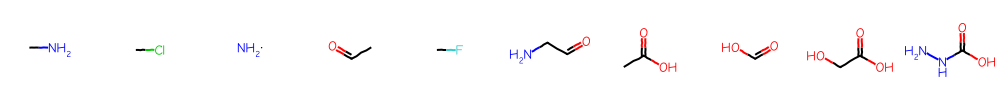

L-amino acid
L-amino acid MATCHES 995


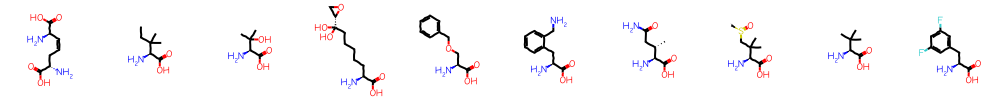

D-amino acid
D-amino acid MATCHES 118


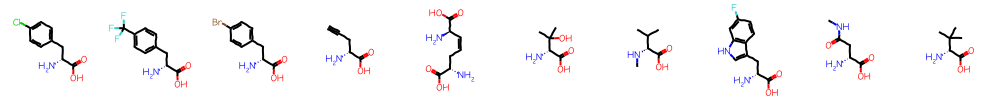

β-amino acid
β-amino acid MATCHES 88


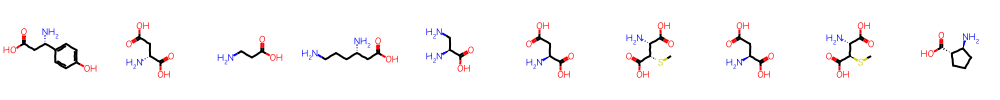

γ-amino acid
γ-amino acid MATCHES 41


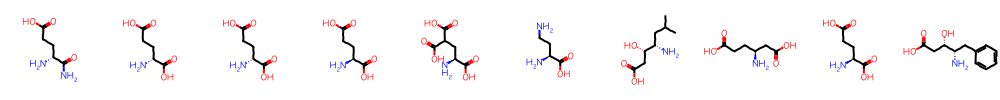

In [36]:
# draw the subsets

for aa_mol in classAA_dict.keys():
    print(aa_mol)
    print(f"{aa_mol} MATCHES {len(classAA_dict[aa_mol]['mol_matching'])}")
    img = Draw.MolsToGridImage(classAA_dict[aa_mol]['mol_matching'][:10], molsPerRow=10, subImgSize=(100,100))
    display(img)

# NOVEMBER 2026
# caps 25
# L-amino acid MATCHES 995
# D-amino acid MATCHES 118
# β-amino acid MATCHES 88
# γ-amino acid MATCHES 41
    
# APRIL 2026
# caps 25
# L-amino acid MATCHES 975
# D-amino acid MATCHES 116
# β-amino acid MATCHES 84
# γ-amino acid MATCHES 39

In [38]:
ncaa_classes_df.to_csv("mondet-2026-Nov-Waldherr-Freimann-noncanonical-classes.csv", sep=";")

### Compare those not in $\alpha, \beta, \gamma$

**Apr. 2026**

* Total from L, D, $\beta, \gamma$ search: **1187** 
* Duplicates: **36**
* Total from children search: **1322**
* Total from children search: **1323**
* + L-search: **1322**
* + D-search: **1322**

In [40]:
positive_list = beta_list + gamma_list + L_list + D_list + methyl_list + ester_list

In [42]:
len(positive_list), len(set(positive_list))

In [84]:
len(negative_examples)

1322

In [86]:
print('Not found by large search, only as children: ', set(negative_examples) - set(positive_list))

Not found by large search, only as children:  {'BB6', 'MY2', 'CR7', 'LYP', '1JM', 'ASL', 'PDW', 'A1BIT', 'NRQ', 'V7T', 'OEM', 'MH8', 'C0F', 'PQ4', '3WX', 'LKE', 'EJJ', 'MK8', 'CQ1', 'A1BE5', 'SAR', 'CWR', 'MDH', '0XQ', '1AC', 'DBU', 'FGL', 'KZV', 'MSA', 'A0G', '5SQ', 'QYG', 'A1LTQ', 'CQ2', 'CR2', 'GIC', 'XY5', 'HGM', 'VYA', 'DAM', 'NLO', 'IEY', 'PIA', 'GLY', 'MDO', 'NMC', 'XDD', 'T7H', 'VME', 'CJO', 'A1CTT', 'UAL', 'KY4', '6ZS', 'I4G', 'T17', 'CFY', 'X1B', 'A1L2U', 'ZI0', '0Y9', '2ML', 'CH6', 'A1BEB', 'RC7', '4N3', 'HJY', '22W', '4M9', 'M3V', 'CRO', '0EH', 'MCQ', 'KZ4', 'OHD', 'MX4', 'MY3', '4NT', 'AC5', 'TUK', 'DNG', 'SQ6', '3A5', 'MLL', 'MY1', 'AIB', 'CIV', 'CLV', 'DSE', 'CPC', 'OIM', 'GZB', 'IO8', 'KZG', '5GM', 'CCY', 'UYA', 'GMO', 'CRX', 'X6E', 'SOW', '2QY', 'GYS', 'YBR', 'MKD', 'ZJU', '02K', 'EYG', 'X9Q', 'V3E', 'X5H', '4NU', 'B2C', 'HSL', 'LLP', '2JN', 'AA1', 'SGK', 'KZ1', 'CRQ', 'MY0', 'A1D5B', 'QYX', 'OFM', 'NTA', '04Q', 'CRK', '45W', 'MJ1', 'A1JND', 'ZAE', 'KWS', 'KXV', 'ILM',

# Appendix

* get V3000 files → SMARTS was easier to use eventually
* save both the matching ID and the matching SMILES → only the matching ID is re

ALA 
     RDKit          2D

  0  0  0  0  0  0  0  0  0  0999 V3000
M  V30 BEGIN CTAB
M  V30 COUNTS 6 5 0 0 0
M  V30 BEGIN ATOM
M  V30 1 C -0.432000 1.250400 0.000000 0
M  V30 2 C -0.432800 0.250400 0.000000 0
M  V30 3 C 0.432800 -0.250400 0.000000 0
M  V30 4 O 1.299200 0.249000 0.000000 0
M  V30 5 O 0.432000 -1.250400 0.000000 0
M  V30 6 N -1.299200 -0.249000 0.000000 0
M  V30 END ATOM
M  V30 BEGIN BOND
M  V30 1 1 2 1 CFG=1
M  V30 2 1 2 3
M  V30 3 2 3 4
M  V30 4 1 3 5
M  V30 5 1 2 6
M  V30 END BOND
M  V30 END CTAB
M  END

ARG 
     RDKit          2D

  0  0  0  0  0  0  0  0  0  0999 V3000
M  V30 BEGIN CTAB
M  V30 COUNTS 12 11 0 0 0
M  V30 BEGIN ATOM
M  V30 1 C -0.360800 -0.041983 0.000000 0
M  V30 2 C 0.505600 -0.541183 0.000000 0
M  V30 3 C 0.506400 -1.541183 0.000000 0
M  V30 4 C 1.372800 -2.040583 0.000000 0
M  V30 5 O 2.238400 -1.539983 0.000000 0
M  V30 6 O 1.373600 -3.040583 0.000000 0
M  V30 7 N -0.359200 -2.041983 0.000000 0
M  V30 8 C -0.361600 0.958017 0.000000 0
M  V30 9 

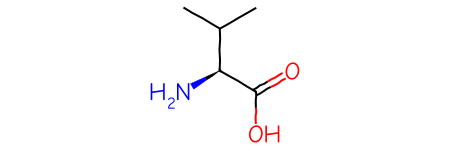

In [174]:
########################
# get V3000 files      #
########################

# get the fingerprints for the canonical amino acids
data = []

for aa, smiles in zip(canonicalAAs, canonicalAA_smiles):
    mol = Chem.MolFromSmiles(smiles)
    block = Chem.MolToMolBlock(mol, forceV3000=True)
    print(aa, block)
    fp = Chem.PatternFingerprint(mol, fpSize=1024, tautomerFingerprints=True)
    smi = Chem.MolToSmiles(mol)

    # add the generated smiles and fingerprint to the data list
    data.append((smi, fp))

qmol = Chem.AdjustQueryProperties(mol)
qmol
# bndl = rdMolEnumerator.Enumerate(query)
# bndl

[07:30:25] WARNING: final character of V3000 array is not ')'


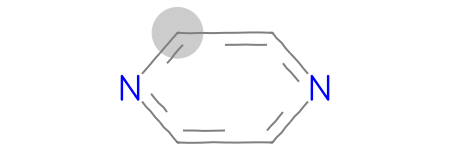

In [160]:
qry = Chem.MolFromMolBlock('''
HISTIDINE_QUERY  08052607192D          

  0  0  0     0  0            999 V3000
M  V30 BEGIN CTAB
M  V30 COUNTS 6 6 0 0 0
M  V30 BEGIN ATOM
M  V30 1 N -1.5000 -0.8660 0 0
M  V30 2 C -0.7500 0.0000 0 0
M  V30 3 C 0.7500 0.0000 0 0
M  V30 4 N 1.5000 -0.8660 0 0
M  V30 5 C 0.7500 -1.7320 0 0
M  V30 6 C -0.7500 -1.7320 0 0
M  V30 END ATOM
M  V30 BEGIN BOND
M  V30 1 5 1 2
M  V30 2 5 2 3
M  V30 3 5 3 4
M  V30 4 5 4 5
M  V30 5 5 5 6
M  V30 6 5 6 1 ENDPTS=(1 2 3) ATTACH=ANY
M  V30 END BOND
M  V30 END CTAB
M  END
''')
qry

### b) ncAA SMILES loading

In [126]:
###################################################################
# iterate over all canonical AAs and find those ncAAs which match #
###################################################################

matching_dict = {}
mol_matching_dict = {}

for aa, aa_smiles in zip(canonicalAAs, canonicalAA_smiles):

    aa_qry = Chem.MolFromSmarts(aa_smiles)
    aa_matching = []
    mol_matching = []

    for SMILES, ID in zip(

        try:
            mol = Chem.MolFromSmiles(SMILES)
            
            if mol.HasSubstructMatch(aa_qry, useChirality=False): #, useChirality=False, useEnhancedStereo=False, NoImplicitH ):
                aa_matching.append(ID)
                mol_matching.append(mol)
        except:
            print(ID)  # A1IPL, A1ITS, WGB, 2AS create problems
            
    matching_dict[f'{aa}'] = aa_matching
    mol_matching_dict[f'{aa}'] = mol_matching

[23:13:54] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 5 C, 6, is greater than permitted
[23:13:54] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 1 As, 6, is greater than permitted
[23:13:54] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 5 C, 6, is greater than permitted


WGB
2AS
A1IPL
A1ITS
WGB
2AS


[23:13:54] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 1 As, 6, is greater than permitted
[23:13:54] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 5 C, 6, is greater than permitted
[23:13:54] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 1 As, 6, is greater than permitted


A1IPL
A1ITS
WGB
2AS
A1IPL
A1ITS


[23:13:54] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 5 C, 6, is greater than permitted
[23:13:54] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:54] Explicit valence for atom # 1 As, 6, is greater than permitted
[23:13:55] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:55] Explicit valence for atom # 5 C, 6, is greater than permitted


WGB
2AS
A1IPL
A1ITS
WGB
2AS


... (24 outputs left out)

[23:13:58] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:58] Explicit valence for atom # 1 As, 6, is greater than permitted
[23:13:58] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:58] Explicit valence for atom # 5 C, 6, is greater than permitted


A1IPL
A1ITS
WGB
2AS


[23:13:58] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:58] Explicit valence for atom # 1 As, 6, is greater than permitted
[23:13:58] Explicit valence for atom # 10 N, 4, is greater than permitted
[23:13:58] Explicit valence for atom # 5 C, 6, is greater than permitted
[23:13:58] Explicit valence for atom # 0 B, 4, is greater than permitted
[23:13:58] Explicit valence for atom # 1 As, 6, is greater than permitted


A1IPL
A1ITS
WGB
2AS
A1IPL
A1ITS


In [127]:
# sanity check if the substructure search worked

for aa in canonicalAAs:
    
    if aa in matching_dict[f'{aa}']:
        print(f'{aa} has found itself')
    elif aa not in matching_dict[f'{aa}']:
        print(f'! {aa} has NOT FOUND itself')

ALA has found itself
ARG has found itself
ASN has found itself
ASP has found itself
CYS has found itself
GLN has found itself
GLU has found itself
GLY has found itself
HIS has found itself
ILE has found itself
LEU has found itself
LYS has found itself
MET has found itself
PHE has found itself
PRO has found itself
SER has found itself
THR has found itself
TRP has found itself
TYR has found itself
VAL has found itself


### c) Clean the list for redundancy

The `matching_dict` is redundant, in the way that any structure which is a substructure of tryptophan will also, e.g., be listed in the alanine list. Thus we have to filter it down sequentially:

Start with ...

* Trp - Tyr - Phe
* His - Lys - Arg - Ile - Leu - Met - Pro
* Lys - Gln - Asn
* Glu - Asp
* Cys - Thr - Val
* Ala - Ser
* Gly

... end with.

In [128]:
priorities = ['TRP', 'TYR', 'PHE', 'HIS', 'LYS', 'ARG', 'ILE', 'LEU', 'MET', 'PRO', 
              'LYS', 'GLN', 'ASN', 'GLU', 'ASP', 
              'CYS', 'THR', 'VAL', 'ALA', 'SER', 'GLY']

#########################
# def FILTER_LIST       #
#########################

def remove_redundancy(restrictive_molecule_list, small_molecule_list):

    [small_molecule_list.remove(ncaa) for ncaa in restrictive_molecule_list]
    
    return small_molecule_list


for aa in priorities:   # go priority-stepwise
    
    for aa_for_deletions in matching_dict.keys():

        if aa == aa_for_deletions:   # do not target the priority's current own list
            continue
            
        elif aa != aa_for_deletions:
            try:
                matching_dict[aa_for_deletions] = remove_redundancy(matching_dict[aa], matching_dict[aa_for_deletions])  # delete from all other lists 
                mol_matching_dict[aa_for_deletions] = remove_redundancy(mol_matching_dict[aa], mol_matching_dict[aa_for_deletions])  # delete from all other lists
            except:
                pass

In [129]:
# sanity check if the deletions did not delete themselves

for aa in canonicalAAs:
    
    if aa in matching_dict[f'{aa}']:
        print(f'{aa} has found itself and has {len(matching_dict[f'{aa}'])} derivates')
    elif aa not in matching_dict[f'{aa}']:
        print(f'! {aa} has NOT FOUND itself')

# sanity check if the deletions did remove correctly

# canonical_set = set(canonicalAAs)
# for aa in canonicalAAs:
#    for aa in matching_dict.keys():
#        aa_set = set(matching_dict[f'{aa}'])    
#        print(f'{aa} contains {aa_set & canonical_set} canonicals')

ALA has found itself and has 700 derivates
ARG has found itself and has 5 derivates
ASN has found itself and has 12 derivates
ASP has found itself and has 24 derivates
CYS has found itself and has 141 derivates
GLN has found itself and has 26 derivates
GLU has found itself and has 15 derivates
GLY has found itself and has 162 derivates
HIS has found itself and has 4 derivates
ILE has found itself and has 23 derivates
LEU has found itself and has 66 derivates
LYS has found itself and has 6 derivates
MET has found itself and has 17 derivates
PHE has found itself and has 106 derivates
PRO has found itself and has 63 derivates
SER has found itself and has 72 derivates
THR has found itself and has 80 derivates
TRP has found itself and has 47 derivates
TYR has found itself and has 65 derivates
VAL has found itself and has 34 derivates


ALA MATCHES


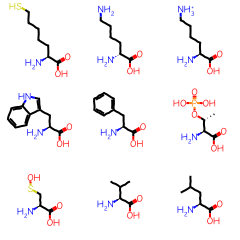

ARG MATCHES


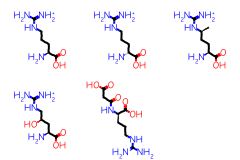

ASN MATCHES


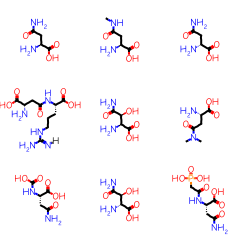

ASP MATCHES


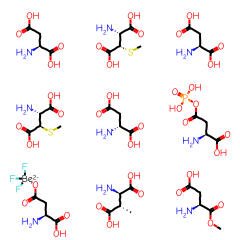

CYS MATCHES


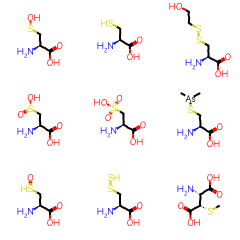

GLN MATCHES


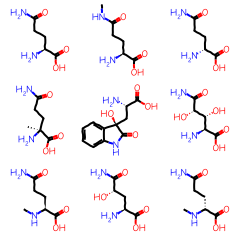

GLU MATCHES


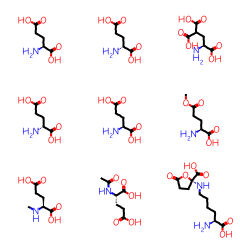

GLY MATCHES


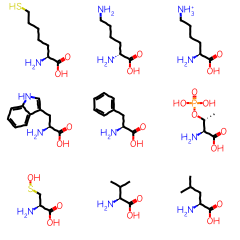

HIS MATCHES


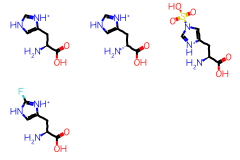

ILE MATCHES


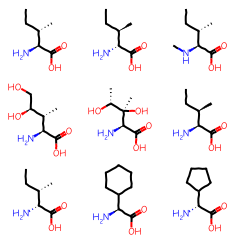

LEU MATCHES


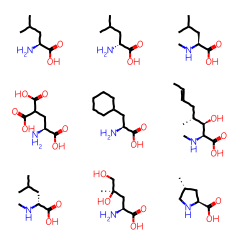

LYS MATCHES


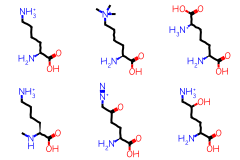

MET MATCHES


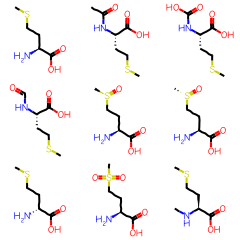

PHE MATCHES


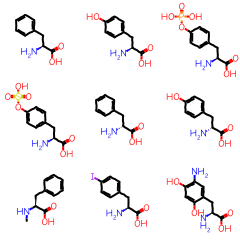

PRO MATCHES


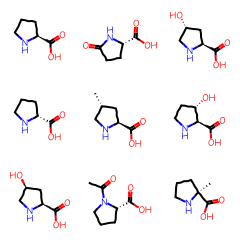

SER MATCHES


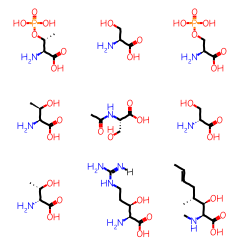

THR MATCHES


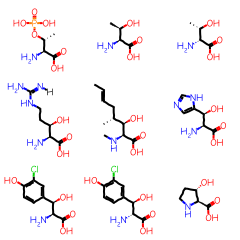

TRP MATCHES


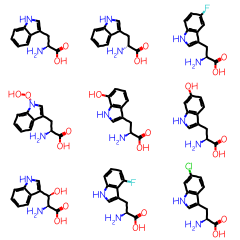

TYR MATCHES


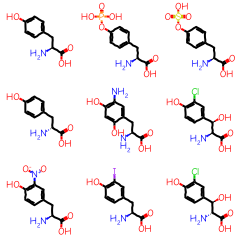

VAL MATCHES


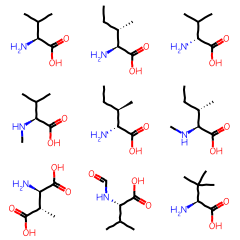

In [134]:
# draw the subsets

for aa_mol in mol_matching_dict.keys():
    print(f"{aa_mol} MATCHES")
    img = Draw.MolsToGridImage(mol_matching_dict[aa_mol][:9], subImgSize=(80,80))
    display(img)

### d) Save the subsets

In [106]:
print('VAL:', matching_dict['VAL'], '\n')
print('TYR:', matching_dict['TYR'], '\n')
print('TRP:', matching_dict['TRP'], '\n')
print('THR:', matching_dict['THR'], '\n')
print('SER:', matching_dict['SER'], '\n')
print('PRO:', matching_dict['PRO'], '\n')
print('PHE:', matching_dict['PHE'], '\n')
print('MET:', matching_dict['MET'], '\n')
print('LYS:', matching_dict['LYS'], '\n')
print('LEU:', matching_dict['LEU'], '\n')
print('ILE:', matching_dict['ILE'], '\n')
print('HIS:', matching_dict['HIS'], '\n')
print('GLY:', matching_dict['GLY'], '\n')
print('GLU:', matching_dict['GLU'], '\n')
print('GLN:', matching_dict['GLN'], '\n')
print('CYS:', matching_dict['CYS'], '\n')
print('ASP:', matching_dict['ASP'], '\n')
print('ASN:', matching_dict['ASN'], '\n')
print('ARG:', matching_dict['ARG'], '\n')
print('ALA:', matching_dict['ALA'], '\n')

VAL: ['VAL', 'DVA', 'MVA', 'ACB', 'FVA', 'TBG', 'LE1', '2GX', 'VME', 'WVL', 'EU0', 'DHV', 'A1A8T', '66E', 'MV9', 'A1I9G', 'DMK', 'HVA', 'ZQN', '4N3', '41H', 'V9M', 'TDD', '0Y9', '34E', 'A1L3I', 'CPC', 'A1ECM', 'A1AVU', 'LVN', 'O7G', 'LEI', 'LAV', 'M2S'] 

TYR: ['TYR', 'PTR', 'TYS', 'DTY', 'TYQ', 'OMY', 'NIY', 'IYR', 'OMZ', 'DAH', 'TYI', '0A1', 'U2X', '3MY', '3CT', 'OTY', 'F2Y', 'TY5', '2LT', 'YOF', 'OMX', '2TY', 'YNM', 'TY2', 'BYR', 'FY3', '2R3', 'DI7', '0WZ', 'DBY', 'HTY', 'PTH', 'T44', '4LZ', 'TY8', 'N9K', 'TY9', 'ZDJ', 'ZT6', 'ZTG', '3YM', 'PTM', 'P3Q', 'P2Q', '1OP', 'T0I', '0EA', 'WET', '22G', 'QCN', 'TYN', 'TYJ', '05O', 'FY2', 'FLT', 'A30', 'A1AP1', 'CNT', 'A1D5P', 'F93', 'NBQ', 'MBQ', '51T', 'J2F', 'HT0'] 

TRP: ['TRP', 'DTR', 'FTR', 'TOX', '0AF', 'TRX', 'UX8', '4FW', '6CW', 'TRO', 'HTR', '4HT', 'TNQ', 'WRP', '4IN', '5CW', 'E9M', 'I3D', '0UO', 'TRF', '1TQ', 'FT6', 'TIG', 'TOQ', 'TTQ', 'A1A2Y', 'BTR', 'PAT', 'V6W', 'SZF', 'TFW', 'TGH', 'WWB', 'Q2E', 'E03', '6G5', 'F7P', 'EXL', 'F7